## Step 0: Install and import

In [4]:
import re, collections
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from spacy.tokens import Doc, Span
from spacy.matcher import PhraseMatcher, Matcher
from spacy.util import filter_spans

N_EVAL = 3000 

## 1. Load the data and explore it

In [5]:
LABEL_MAP = {
    "per": "PER", "person": "PER",
    "org": "ORG",
    "loc": "LOC", "geo": "LOC", "gpe": "LOC",
    "misc": "MISC", "tim": "MISC", "art": "MISC", "eve": "MISC", "nat": "MISC",
}


INT2TAG = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]


def norm_tag(t):
    if isinstance(t, int) or (isinstance(t, str) and t.strip().isdigit()):
        idx = int(t)
        if not 0 <= idx < len(INT2TAG):
            raise ValueError(f"Invalid tag ID: {idx}")
        t = INT2TAG[idx]

    t = str(t).strip()
    if t.upper() == "O" or t.lower() in ("", "nan"):
        return "O"

    prefix, sep, lab = t.partition("-")
    if not sep:
        raise ValueError(f"Invalid NER tag format: {t}")

    prefix = prefix.upper()
    lab = LABEL_MAP.get(lab.lower(), lab.upper())
    if prefix not in ("B", "I") or lab not in set(LABEL_MAP.values()):
        raise ValueError(f"Unknown NER tag: {t}")

    return f"{prefix}-{lab}"

In [6]:

from datasets import load_dataset

conll = load_dataset("lhoestq/conll2003")

def load_hf_sentences(split):
    result = []

    for row in conll[split]:
        words = row["tokens"]
        tags = [norm_tag(tag) for tag in row["ner_tags"]]

        if len(words) != len(tags):
            raise ValueError("Token/tag count mismatch")

        result.append((words, tags))

    return result


train = load_hf_sentences("train")
validation = load_hf_sentences("validation")
test = load_hf_sentences("test")

print(
    f"train sentences: {len(train):,} | "
    f"validation sentences: {len(validation):,} | "
    f"test sentences: {len(test):,}"
)

print("\nFirst training sentence:")
print(train[0])

print("\nFirst testing sentence:")
print(test[0])


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train sentences: 14,041 | validation sentences: 3,250 | test sentences: 3,453

First training sentence:
(['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.'], ['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O'])

First testing sentence:
(['SOCCER', '-', 'JAPAN', 'GET', 'LUCKY', 'WIN', ',', 'CHINA', 'IN', 'SURPRISE', 'DEFEAT', '.'], ['O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'B-PER', 'O', 'O', 'O', 'O'])


,sentence,word,tag
0,0,EU,B-ORG
1,0,rejects,O
2,0,German,B-MISC
3,0,call,O
4,0,to,O
5,0,boycott,O
6,0,British,B-MISC
7,0,lamb,O
8,0,.,O
9,1,Peter,B-PER


tag
O         169578
B-LOC       7140
B-PER       6600
B-ORG       6321
I-PER       4528
I-ORG       3704
B-MISC      3438
I-LOC       1157
I-MISC      1155
Name: count, dtype: int64

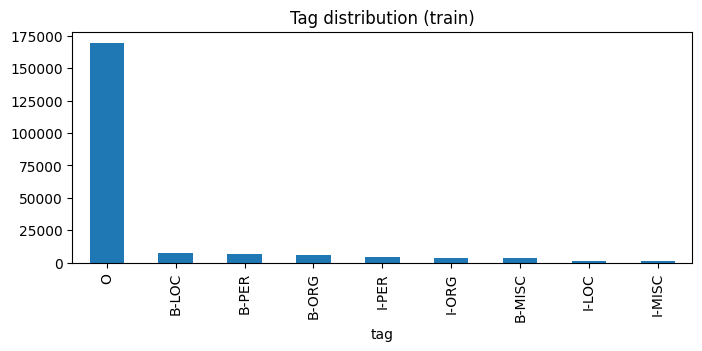

In [7]:
def to_token_df(data):
    return pd.DataFrame([(i, w, t) for i, (ws, ts) in enumerate(data) for w, t in zip(ws, ts)],
                        columns=["sentence", "word", "tag"])

tok_df = to_token_df(train)
display(tok_df.head(10))
tag_counts = tok_df["tag"].value_counts()
display(tag_counts)
tag_counts.plot.bar(title="Tag distribution (train)", figsize=(8, 3)); plt.show()

## 2. BIO tags 

In [8]:
def bio_to_spans(tags):
    """['B-PER','I-PER','O','B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]  (end is exclusive)"""
    spans, start, lab = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t == "O" or t.startswith("B-") or (t.startswith("I-") and t[2:] != lab):
            if start is not None:
                spans.append((start, i, lab)); start, lab = None, None
            if t != "O":
                start, lab = i, t[2:]
    return spans

print(bio_to_spans(train[0][1]))
entity_counts = collections.Counter(l for _, tags in train for _, _, l in bio_to_spans(tags))
print(entity_counts)

[(0, 1, 'ORG'), (2, 3, 'MISC'), (6, 7, 'MISC')]
Counter({'LOC': 7140, 'PER': 6600, 'ORG': 6321, 'MISC': 3438})


## 3. Rule-based NER

In [9]:
def build_gazetteer(data, min_count=2):
    cnt = collections.defaultdict(collections.Counter)
    for words, tags in data:
        for s, e, l in bio_to_spans(tags):
            cnt[" ".join(words[s:e])][l] += 1
    gaz = collections.defaultdict(list)
    for text, c in cnt.items():
        if sum(c.values()) >= min_count and len(text) > 2 and (text[0].isupper() or text[0].isdigit()):
            gaz[c.most_common(1)[0][0]].append(text)     
    return gaz

TITLES = ["mr", "mr.", "mrs", "mrs.", "ms", "ms.", "dr", "dr.", "president", "minister", "prime", "sen.",
          "senator", "gen.", "general", "coach", "captain", "king", "queen", "prince", "judge", "mayor"]
ORG_SUFFIX = ["inc", "inc.", "corp", "corp.", "ltd", "ltd.", "co", "co.", "plc", "bank", "university", "ministry",
              "party", "council", "association", "union", "club", "commission", "agency"]

class RuleNER:
    def __init__(self, vocab, gazetteer):
        self.vocab = vocab
        self.pm = PhraseMatcher(vocab, attr="ORTH")
        for label, names in gazetteer.items():
            self.pm.add(label, [Doc(vocab, words=n.split(" ")) for n in names])
        self.m = Matcher(vocab)
        self.m.add("PER_TITLE", [[{"LOWER": {"IN": TITLES}}, {"IS_TITLE": True}, {"IS_TITLE": True, "OP": "?"}]])
        self.m.add("ORG", [[{"IS_TITLE": True, "OP": "+"}, {"LOWER": {"IN": ORG_SUFFIX}}]])

    def __call__(self, doc):
        spans = []
        for mid, s, e in self.pm(doc):
            spans.append(Span(doc, s, e, label=self.vocab.strings[mid]))
        for mid, s, e in self.m(doc):
            name = self.vocab.strings[mid]
            if name == "PER_TITLE":
                spans.append(Span(doc, s + 1, e, label="PER"))     
            else:
                spans.append(Span(doc, s, e, label=name))
        doc.ents = filter_spans(spans)                              
        return doc

gaz = build_gazetteer(train)
print({k: len(v) for k, v in gaz.items()}, "gazetteer entries")
rule_ner = RuleNER(spacy.blank("en").vocab, gaz)

{'MISC': 366, 'LOC': 603, 'ORG': 1075, 'PER': 1177} gazetteer entries


## 4. Model-based NER

In [10]:
nlp_sm = spacy.load("en_core_web_sm")
nlp_md = spacy.load("en_core_web_md")


SPACY2CONLL = {"PERSON": "PER", "ORG": "ORG", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC",
               "NORP": "MISC", "EVENT": "MISC", "WORK_OF_ART": "MISC", "PRODUCT": "MISC",
               "LANGUAGE": "MISC", "LAW": "MISC"}           

def run_spacy(nlp):
    def _run(doc):
        for _, proc in nlp.pipeline:
            doc = proc(doc)
        spans = [Span(doc, e.start, e.end, label=SPACY2CONLL[e.label_])
                 for e in doc.ents if e.label_ in SPACY2CONLL]
        doc.ents = spans
        return doc
    return _run

SYSTEMS = {
    "rule-based":       (spacy.blank("en").vocab, rule_ner),
    "spaCy sm":         (nlp_sm.vocab, run_spacy(nlp_sm)),
    "spaCy md":         (nlp_md.vocab, run_spacy(nlp_md)),
}

def predict(system, words):
    vocab, fn = SYSTEMS[system]
    return fn(Doc(vocab, words=words))     

## 5. Evaluation

In [11]:
def evaluate(system, data, n=None):
    tp, fp, fn = (collections.Counter() for _ in range(3))
    for words, tags in data[:n]:
        gold = set(bio_to_spans(tags))
        pred = {(e.start, e.end, e.label_) for e in predict(system, words).ents}
        for s in pred & gold: tp[s[2]] += 1
        for s in pred - gold: fp[s[2]] += 1
        for s in gold - pred: fn[s[2]] += 1
    rows = []
    for lab in ["PER", "ORG", "LOC", "MISC", "ALL"]:
        T = sum(tp.values()) if lab == "ALL" else tp[lab]
        F = sum(fp.values()) if lab == "ALL" else fp[lab]
        N = sum(fn.values()) if lab == "ALL" else fn[lab]
        p = T / (T + F) if T + F else 0.0
        r = T / (T + N) if T + N else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        rows.append({"system": system, "label": lab, "precision": p, "recall": r, "f1": f, "support": T + N})
    return pd.DataFrame(rows)

results = pd.concat([evaluate(s, test, N_EVAL) for s in SYSTEMS], ignore_index=True)
display(results.round(3))

,system,label,precision,recall,f1,support
0,rule-based,PER,0.627,0.116,0.195,1452
1,rule-based,ORG,0.810,0.448,0.577,1266
2,rule-based,LOC,0.891,0.744,0.811,1545
3,rule-based,MISC,0.807,0.620,0.701,647
4,rule-based,ALL,0.829,0.466,0.596,4910
5,spaCy sm,PER,0.736,0.588,0.654,1452
6,spaCy sm,ORG,0.424,0.359,0.389,1266
7,spaCy sm,LOC,0.800,0.740,0.769,1545
8,spaCy sm,MISC,0.684,0.564,0.618,647
9,spaCy sm,ALL,0.672,0.574,0.619,4910


## 6. Categorize entities

In [12]:
COLORS  = {"PER": "#ffd166", "ORG": "#8ecae6", "LOC": "#a7e8bd", "MISC": "#f4a6c6"}
OPTIONS = {"ents": list(COLORS), "colors": COLORS}


article_words = []
for words, tags in test:
    if len(bio_to_spans(tags)) >= 2:
        article_words += words
    if len(article_words) > 120:
        break
print(" ".join(article_words))

SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT . AL-AIN , United Arab Emirates 1996-12-06 Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday . But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcomers Uzbekistan . China controlled most of the match and saw several chances missed until the 78th minute when Uzbek striker Igor Shkvyrin took advantage of a misdirected defensive header to lob the ball over the advancing Chinese keeper and into an empty net . The former Soviet republic was playing in an Asian Cup finals tie for the first time .


In [13]:
for system in SYSTEMS:
    print(f"\n=== {system} ===")
    doc = predict(system, article_words)
    displacy.render(doc, style="ent", options=OPTIONS, jupyter=True)


=== rule-based ===



=== spaCy sm ===



=== spaCy md ===


In [14]:

def entities_df(doc, system):
    return pd.DataFrame([(system, e.text, e.label_) for e in doc.ents], columns=["system", "entity", "label"])

ents = pd.concat([entities_df(predict(s, article_words), s) for s in SYSTEMS], ignore_index=True)
summary = (ents.groupby(["system", "label"])["entity"]
               .agg(count="count", entities=lambda x: ", ".join(sorted(set(x)))).reset_index())
display(summary)


big = pd.DataFrame([(e.text, e.label_) for words, _ in test[:1000] for e in predict("spaCy md", words).ents],
                   columns=["entity", "label"])
for lab in COLORS:
    print(lab, "->", big[big.label == lab]["entity"].value_counts().head(8).to_dict())

,system,label,count,entities
0,rule-based,LOC,4,"China, Japan, Syria"
1,rule-based,MISC,7,"Arab, Asian, Chinese, Cup, Soviet"
2,rule-based,ORG,1,United
3,spaCy md,LOC,8,"China, Japan, SURPRISE, Soviet republic, Syria..."
4,spaCy md,MISC,4,"Asian Cup, Chinese, Uzbek, an Asian Cup"
5,spaCy md,ORG,2,"Group C, SOCCER - JAPAN"
6,spaCy md,PER,1,Igor Shkvyrin
7,spaCy sm,LOC,7,"China, DEFEAT, Japan, Syria, United Arab Emira..."
8,spaCy sm,MISC,4,"Asian Cup, Chinese, Soviet, Uzbek"
9,spaCy sm,ORG,1,Group C


PER -> {'Bitar': 6, 'Zywiec': 6, 'Albright': 6, 'Van Boxmeer': 5, 'Rosati': 5, 'Klaus': 4, 'Lara': 4, 'Havel': 4}
ORG -> {'W L': 8, 'Reuters': 7, 'Real Madrid': 6, 'FIFA': 6, 'ODS': 5, 'MADRID': 4, 'AC Milan': 4, 'EASTERN': 4}
LOC -> {'Australia': 27, 'China': 15, 'West Indies': 14, 'Japan': 13, 'Barcelona': 11, 'England': 11, 'Indonesia': 11, 'Poland': 11}
MISC -> {'Czech': 13, 'Polish': 8, 'Swiss': 7, 'French': 6, 'Syrian': 6, 'Italian': 5, 'the World Series': 4, 'European': 4}


In [15]:
doc = predict("spaCy md", article_words)

html = displacy.render(
    doc,
    style="ent",
    options=OPTIONS,
    page=True,
    jupyter=False
)

with open("ner_displacy_spacy_md.html", "w", encoding="utf-8") as f:
    f.write(html)

print("Saved ner_displacy_spacy_md.html")


Saved ner_displacy_spacy_md.html


## 7. Compare the models

system,rule-based,spaCy md,spaCy sm
label,,,
PER,0.195,0.707,0.654
ORG,0.577,0.409,0.389
LOC,0.811,0.773,0.769
MISC,0.701,0.646,0.618
ALL,0.596,0.648,0.619


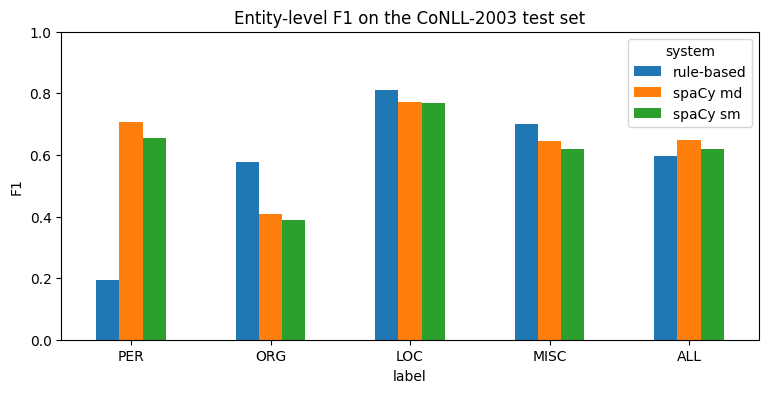

In [16]:
pivot = results.pivot(index="label", columns="system", values="f1").loc[["PER", "ORG", "LOC", "MISC", "ALL"]]
display(pivot.round(3))
pivot.plot.bar(figsize=(9, 4), title="Entity-level F1 on the CoNLL-2003 test set", ylim=(0, 1))
plt.ylabel("F1"); plt.xticks(rotation=0); plt.show()

In [17]:
rows = []
for words, tags in test[:N_EVAL]:
    sm = {(e.start, e.end, e.label_) for e in predict("spaCy sm", words).ents}
    md_ = {(e.start, e.end, e.label_) for e in predict("spaCy md", words).ents}
    if sm != md_:
        fmt = lambda S: [(" ".join(words[s:e]), l) for s, e, l in sorted(S)]
        rows.append({"sentence": " ".join(words), "sm": fmt(sm), "md": fmt(md_),
                     "gold": [(" ".join(words[s:e]), l) for s, e, l in bio_to_spans(tags)]})
diff = pd.DataFrame(rows)
print(f"{len(diff)} sentences where sm and md disagree")
pd.set_option("display.max_colwidth", 120)
display(diff.head(10))

1196 sentences where sm and md disagree


,sentence,sm,md,gold
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .","[(DEFEAT, ORG)]","[(SOCCER - JAPAN, ORG), (SURPRISE, LOC)]","[(JAPAN, LOC), (CHINA, PER)]"
1,"AL-AIN , United Arab Emirates 1996-12-06","[(AL-AIN, ORG), (United Arab Emirates, LOC)]","[(United Arab Emirates, LOC)]","[(AL-AIN, LOC), (United Arab Emirates, LOC)]"
2,"But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcome...","[(China, LOC), (Uzbekistan, ORG)]","[(China, LOC), (Uzbekistan, LOC)]","[(China, LOC), (Uzbekistan, LOC)]"
3,"Oleg Shatskiku made sure of the win in injury time , hitting an unstoppable left foot shot from just outside the area .",[],"[(Oleg Shatskiku, PER)]","[(Oleg Shatskiku, PER)]"
4,The former Soviet republic was playing in an Asian Cup finals tie for the first time .,"[(Soviet, MISC)]","[(Soviet republic, LOC), (an Asian Cup, MISC)]","[(Soviet, MISC), (Asian Cup, MISC)]"
5,"Despite winning the Asian Games title two years ago , Uzbekistan are in the finals as outsiders .","[(the Asian Games, MISC), (Uzbekistan, MISC)]","[(Asian Games, ORG), (Uzbekistan, LOC)]","[(Asian Games, MISC), (Uzbekistan, LOC)]"
6,"Takuya Takagi scored the winner in the 88th minute , rising to head a Hiroshige Yanagimoto cross towards the Syrian ...","[(Takuya Takagi, PER), (Hiroshige Yanagimoto, PER), (Syrian, MISC), (Salem Bitar, ORG)]","[(Takuya Takagi, PER), (Hiroshige Yanagimoto, PER), (Syrian, MISC), (Salem Bitar, PER)]","[(Takuya Takagi, PER), (Hiroshige Yanagimoto, PER), (Syrian, MISC), (Salem Bitar, PER)]"
7,Defender Hassan Abbas rose to intercept a long ball into the area in the 84th minute but only managed to divert it i...,"[(Defender Hassan Abbas, PER), (Bitar, PER)]","[(Hassan Abbas, PER), (Bitar, PER)]","[(Hassan Abbas, PER), (Bitar, PER)]"
8,Hosts UAE play Kuwait and South Korea take on Indonesia on Saturday in Group A matches .,"[(Kuwait, LOC), (South Korea, LOC), (Indonesia, LOC), (Group, ORG)]","[(Hosts UAE, ORG), (Kuwait, LOC), (South Korea, LOC), (Indonesia, LOC), (Group A, ORG)]","[(UAE, LOC), (Kuwait, LOC), (South Korea, LOC), (Indonesia, LOC)]"
9,Italy recalled Marcello Cuttitta,"[(Italy, LOC), (Marcello, ORG), (Cuttitta, MISC)]","[(Italy, LOC), (Marcello Cuttitta, PER)]","[(Italy, LOC), (Marcello Cuttitta, PER)]"


## 8. Conclusion

**Overall F1 on the CoNLL-2003 test set**

| System | Precision | Recall | F1 |
|---|---|---|---|
| Rule-based | 0.829 | 0.466 | 0.596 |
| spaCy sm | 0.672 | 0.574 | 0.619 |
| spaCy md | 0.680 | 0.620 | 0.648 |

**Observations**

- **`md` beats `sm`** (F1 0.648 vs 0.619), mainly on PER and recall. The word vectors in `md` help it generalize to names it has not seen before.
- **The rule-based system is precise but misses a lot.** Precision is high (0.83) but recall is low (0.47). It only finds names that are in its gazetteer, so PER recall is very low (F1 0.195) because there are far too many person names to list.
- **The rule-based system is competitive on ORG, LOC and MISC**, because its gazetteer was built from CoNLL training data, which is the same domain as the test set. The spaCy models were trained on a different corpus.
- **ORG is the hardest class for spaCy** (F1 about 0.4). The models were trained on OntoNotes, whose annotation guidelines differ from CoNLL's. For example, sports teams and country names used as teams are labelled differently, so the label mapping can only approximate the CoNLL scheme.
- **CoNLL headlines are written in capital letters** (e.g. `SOCCER - JAPAN GET LUCKY WIN`). This confuses the spaCy models, which rely on capitalization, and words like "SURPRISE" and "DEFEAT" were wrongly tagged as locations.

**Limitations and possible improvements**

- The rule-based gazetteer only covers entities seen in training. A larger gazetteer or a fuzzy matcher would raise recall.
- Fine-tuning a spaCy model directly on CoNLL-2003 would remove the label mismatch and should improve ORG significantly.
- A transformer model (`en_core_web_trf`) could be added as a third comparison.